# 02 · Détecteur de langue (français, anglais, bambara et langues voisines)

**But.** Fabriquer un petit programme qui reconnaît la langue d'une phrase, et qui sait distinguer le **bambara** de langues voisines (wolof, éwé, fon, mooré, haoussa, yoruba), en plus du français et de l'anglais.

**Méthode.** Une approche classique et légère, sans réseau de neurones : on compte les petits morceaux de mots (suites de 1 à 4 lettres, appelées *n-grammes de caractères*), on pondère ces comptes par leur rareté (TF-IDF), et un classifieur apprend quelles suites de lettres signalent quelle langue.

| | |
|---|---|
| **Durée** | quelques minutes |
| **Matériel** | aucun GPU nécessaire |
| **Internet** | oui, premier téléchargement (quelques Mo) |
| **Ce que tu obtiens** | `models/langid.joblib` et `results/langid_confusion.png` |

**Pourquoi des langues voisines ?** Séparer le français de l'anglais est trivial. Distinguer le bambara du mooré ou du fon est un vrai test, car ces langues partagent des lettres spéciales (ɛ, ɔ, ɲ, ŋ).

## 1. Se repérer dans les dossiers

**Objectif.** Retrouver les dossiers du projet.

**Ce que fait la cellule.** Même cellule que dans le notebook 01 : détecte la racine du projet et crée les dossiers manquants.

**Ce que tu dois voir.** Une ligne `Racine du projet : ...`.

In [1]:
import os
from pathlib import Path

# Ces deux réglages évitent des avertissements inutiles de Hugging Face.
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Racine du projet = le dossier qui contient "data", "models", "results", "src"...
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (ROOT / "src").exists():
    raise RuntimeError(
        f"Dossier du projet introuvable depuis {cwd}. "
        "Lance Jupyter avec bash lancer_jupyter.sh (ou depuis le dossier du projet)."
    )

DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"
for folder in (DATA_RAW, DATA_PROC, MODELS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", ROOT)

Racine du projet : /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl


## 2. Construire le jeu de données de langues

**Objectif.** Rassembler des phrases de 9 langues, chacune avec son découpage entraînement / validation / test.

**Ce que fait la cellule.** Les corpus parallèles de Masakhane contiennent, pour chaque paire de langues, deux fichiers texte alignés. On prend un côté de chaque paire (par exemple le côté `.wol` du couple français-wolof). Les fichiers sont téléchargés une seule fois et gardés dans `data/raw/text_files/`. On retire ensuite les doublons et toute phrase qui apparaît dans plusieurs découpages.

**Ce que tu dois voir.** Un tableau de plus de 50 000 phrases, puis une table qui montre, pour chaque langue, le nombre de phrases en `train`, `val` et `test`.

> **Attention.** Le téléchargement de ~9 langues × 3 fichiers peut prendre une à deux minutes la première fois.

In [2]:
import urllib.request
import pandas as pd

GITHUB = "https://raw.githubusercontent.com/masakhane-io/lafand-mt/main/data/text_files"
SPLIT_FILES = {"train": "train", "val": "dev", "test": "test"}

# langue -> (dossier de la paire, extension du fichier)
SOURCES = {
    "fr":  ("fr-bam", "fr"),
    "en":  ("en-hau", "en"),
    "bam": ("fr-bam", "bam"),
    "wol": ("fr-wol", "wol"),
    "ewe": ("fr-ewe", "ewe"),
    "fon": ("fr-fon", "fon"),
    "mos": ("fr-mos", "mos"),
    "hau": ("en-hau", "hau"),
    "yor": ("en-yor", "yor"),
}

def read_lines(pair, split, ext):
    local = DATA_RAW / "text_files" / pair / f"{SPLIT_FILES[split]}.{ext}"
    if local.exists():
        text = local.read_text(encoding="utf-8")
    else:
        url = f"{GITHUB}/{pair}/{SPLIT_FILES[split]}.{ext}"
        with urllib.request.urlopen(url) as resp:
            text = resp.read().decode("utf-8")
        local.parent.mkdir(parents=True, exist_ok=True)
        local.write_text(text, encoding="utf-8")
    return [" ".join(line.split()) for line in text.splitlines() if line.strip()]

rows = []
for lang, (pair, ext) in SOURCES.items():
    for split in SPLIT_FILES:
        for line in read_lines(pair, split, ext):
            rows.append({"text": line, "lang": lang, "split": split})

df = pd.DataFrame(rows).drop_duplicates(subset=["text", "lang", "split"])

# Une phrase présente dans plusieurs découpages est retirée du train (pas de fuite).
held_out = set(df[df["split"] != "train"]["text"])
df = df[~((df["split"] == "train") & df["text"].isin(held_out))].reset_index(drop=True)
print(df.shape)
df.groupby(["lang", "split"]).size().unstack()

(55456, 3)


split,test,train,val
lang,,,
bam,1498,2986,1499
en,1485,3023,1279
ewe,1555,2020,1409
fon,1573,2637,1223
fr,1471,2958,1495
hau,1485,3021,1281
mos,1574,2486,1491
wol,1500,3360,1506
yor,1530,6567,1544


## 3. Équilibrer les classes

**Objectif.** Éviter que le modèle favorise les langues les plus représentées dans les données.

**Ce que fait la cellule.** Plafonne chaque langue à 2 000 phrases d'entraînement, 500 de validation et 500 de test (tirées au hasard, de façon reproductible). Puis affiche une phrase d'exemple par langue.

**Ce que tu dois voir.** Un tableau où toutes les langues ont exactement 2 000 / 500 / 500 phrases, puis neuf exemples de phrases.

> **Attention.** Un modèle entraîné sur 5 000 phrases de français et 500 de fon aurait tendance à répondre « français » dans le doute : c'est le déséquilibre des classes.

In [3]:
CAP = {"train": 2000, "val": 500, "test": 500}

parts = []
for (lang, split), g in df.groupby(["lang", "split"]):
    parts.append(g.sample(n=min(len(g), CAP[split]), random_state=42))
data = pd.concat(parts, ignore_index=True)

train, val, test = (data[data["split"] == s] for s in ("train", "val", "test"))
print({s: len(d) for s, d in zip(("train", "val", "test"), (train, val, test))})

pd.set_option("display.max_colwidth", 110)
display(data.groupby(["lang", "split"]).size().unstack())
data[data["split"] == "train"].groupby("lang").head(1)[["lang", "text"]].reset_index(drop=True)

{'train': 18000, 'val': 4500, 'test': 4500}


split,test,train,val
lang,,,
bam,500,2000,500
en,500,2000,500
ewe,500,2000,500
fon,500,2000,500
fr,500,2000,500
hau,500,2000,500
mos,500,2000,500
wol,500,2000,500
yor,500,2000,500


,lang,text
0,bam,"K 37, nk 18, s 10, f 7, g 1, cd 29, ct 7, +22. 2 – Ɔnzi Kereyatɛri :"
1,en,His Eminence referred to the efforts made by foreign media to magnify certain disagreements among Iran's g...
2,ewe,Wobe atsikutsetsea nana be akaŋunu ɖiɖia kpɔtɔ le ʋume na ame.
3,fon,2205- Bó ná dó liza xá azɔnkwín nɛ́ ɔ́ ɖò lanmɛ ɔ́‚ agbaza ɔ́ ɖesu nɔ bló hùngó tɔn lɛ́ɛ sukpɔ.
4,fr,"D’autant que la justice avait refusé d’autoriser la diffusion des images des caméras-piétons des agents, a..."
5,hau,Mutane su ne za su zabi masu kafa doka.
6,mos,Bõe n yĩng ti boaalã ligd yaa toogo tɩ boaalã wʋʋm yaool n pa wa sẽn segde?
7,wol,Maki Sàll dafa jege askanam loolu mooy dooleem wuutale ko ak Kujjeg pólótig gi amul benn kàttan lu dul nek...
8,yor,--- Roberto Mancini fẹnu kò pẹ̀lú àjọ FA láti tukọ̀ agbábọ́ọ̀lù orílẹ̀-èdè Italy.


## 4. Comparer trois modèles simples

**Objectif.** Choisir le meilleur des trois classifieurs, en se basant sur la **validation** (jamais sur le test).

**Ce que fait la cellule.** Construit un *pipeline* en deux temps : (a) transformer chaque phrase en nombres (TF-IDF sur les n-grammes de 1 à 4 caractères) ; (b) un classifieur. On essaie Naive Bayes, la régression logistique et un SVM linéaire, et on mesure l'accuracy (part de bonnes réponses) et le F1 macro (moyenne du score de chaque langue, qui pénalise une langue ratée même si elle est rare).

**Ce que tu dois voir.** Un tableau de trois lignes avec des scores proches de 0,99. Les trois modèles sont presque à égalité : l'écart entre eux est minuscule et ne prouve rien.

> **Attention.** Règle d'or : le jeu de test ne sert **qu'une seule fois**, à la fin, pour donner le score final. Si on s'en servait pour choisir le modèle, le score serait biaisé.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

def make(clf, ngram=(1, 4)):
    return Pipeline([
        ("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=ngram, sublinear_tf=True)),
        ("clf", clf),
    ])

candidates = {
    "Naive Bayes": make(MultinomialNB(alpha=0.1)),
    "Régression logistique": make(LogisticRegression(max_iter=1000, C=10)),
    "SVM linéaire": make(LinearSVC(C=1.0)),
}

results = []
for name, model in candidates.items():
    model.fit(train["text"], train["lang"])
    pred = model.predict(val["text"])
    results.append({
        "modèle": name,
        "accuracy (val)": round(accuracy_score(val["lang"], pred), 4),
        "F1 macro (val)": round(f1_score(val["lang"], pred, average="macro"), 4),
    })
pd.DataFrame(results)

,modèle,accuracy (val),F1 macro (val)
0,Naive Bayes,0.9956,0.9956
1,Régression logistique,0.9947,0.9947
2,SVM linéaire,0.9960,0.9960


## 5. Évaluation finale sur le test

**Objectif.** Mesurer honnêtement la qualité du modèle retenu sur des phrases jamais utilisées pour choisir ou entraîner.

**Ce que fait la cellule.** Prend le meilleur modèle de la validation, prédit la langue des 4 500 phrases de test et affiche le rapport détaillé (précision, rappel et F1 par langue).

**Ce que tu dois voir.** Une accuracy autour de 0,998. Chaque langue a un F1 proche de 1.

> **Attention.** Un score aussi haut est trompeur : tous les textes viennent de la presse, et des phrases d'un même article partagent noms propres et vocabulaire entre train et test. Sur des SMS ou du bambara écrit sans les lettres spéciales, attends-toi à moins bien.

In [5]:
from sklearn.metrics import classification_report

best_name = max(results, key=lambda r: r["F1 macro (val)"])["modèle"]
model = candidates[best_name]
print("Modèle retenu :", best_name)

pred = model.predict(test["text"])
print(f"accuracy : {accuracy_score(test['lang'], pred):.4f}")
print(f"F1 macro : {f1_score(test['lang'], pred, average='macro'):.4f}\n")
print(classification_report(test["lang"], pred, digits=3))

Modèle retenu : SVM linéaire
accuracy : 0.9987
F1 macro : 0.9987

              precision    recall  f1-score   support

         bam      0.998     0.994     0.996       500
          en      0.998     1.000     0.999       500
         ewe      0.998     1.000     0.999       500
         fon      1.000     1.000     1.000       500
          fr      1.000     0.998     0.999       500
         hau      1.000     1.000     1.000       500
         mos      0.996     1.000     0.998       500
         wol      0.998     0.998     0.998       500
         yor      1.000     0.998     0.999       500

    accuracy                          0.999      4500
   macro avg      0.999     0.999     0.999      4500
weighted avg      0.999     0.999     0.999      4500



## 6. Matrice de confusion

**Objectif.** Voir quelles langues se font confondre entre elles.

**Ce que fait la cellule.** Trace un tableau coloré : chaque ligne est la vraie langue, chaque colonne la langue prédite. Une case sur la diagonale est une bonne réponse, une case hors diagonale est une erreur. L'image est aussi sauvegardée dans `results/`.

**Ce que tu dois voir.** Une diagonale très foncée et presque aucune case colorée ailleurs.

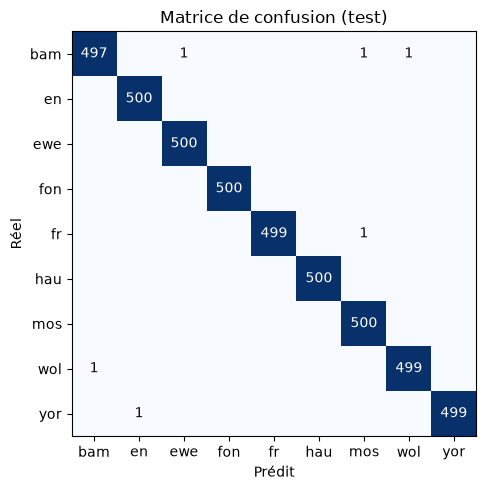

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

labels = sorted(data["lang"].unique())
cm = confusion_matrix(test["lang"], pred, labels=labels)

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion (test)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig(RESULTS / "langid_confusion.png", dpi=150)
plt.show()

## 7. Les erreurs, et la fragilité sur textes courts

**Objectif.** Comprendre où le modèle se trompe et à partir de quelle longueur de texte il devient peu fiable.

**Ce que fait la cellule.** Affiche les phrases mal classées. Puis tronque chaque phrase de test à 10, 20, 40, 80 et 160 caractères et recalcule les scores.

**Ce que tu dois voir.** Environ 6 erreurs sur 4 500, presque toutes des « phrases » quasi vides (un point, un nom propre). Puis un tableau où l'accuracy passe d'environ 0,89 (10 caractères) à plus de 0,99 (40 caractères et plus).

> **Attention.** Moins de 20 caractères, aucun détecteur n'est vraiment fiable : il n'y a pas assez d'information dans le texte.

In [7]:
pd.set_option("display.max_colwidth", 90)
errors = test.assign(pred=pred)
errors = errors[errors["lang"] != errors["pred"]]
print(len(errors), "erreurs sur", len(test), "phrases")
display(errors[["lang", "pred", "text"]].head(15))

rows = []
for n in (10, 20, 40, 80, 160):
    short = test["text"].str.slice(0, n)
    p = model.predict(short)
    rows.append({"caractères": n, "accuracy": round(accuracy_score(test["lang"], p), 4),
                 "F1 macro": round(f1_score(test["lang"], p, average="macro"), 4)})
pd.DataFrame(rows)

6 erreurs sur 4500 phrases


,lang,pred,text
195,bam,ewe,Belebeleba.
249,bam,mos,.
436,bam,wol,Bi.
12120,fr,mos,.
21484,wol,bam,Aamadu Ba
24416,yor,en,Africa Digital Rights Fund àti The Collaboration on International ICT Policy for East ...


,caractères,accuracy,F1 macro
0,10,0.8929,0.8926
1,20,0.9744,0.9745
2,40,0.9944,0.9944
3,80,0.9978,0.9978
4,160,0.9987,0.9987


## 8. Sauvegarder et essayer le détecteur

**Objectif.** Garder le modèle sur le disque pour le réutiliser, et le tester sur tes propres phrases.

**Ce que fait la cellule.** Enregistre le modèle dans `models/langid.joblib`. La fonction `detect` renvoie les trois langues les plus probables avec un score. Pour la régression logistique ce sont des probabilités ; pour le SVM, des scores bruts (plus grand = plus sûr, valeurs négatives possibles).

**Ce que tu dois voir.** Le français est reconnu pour la phrase française, l'anglais pour l'anglaise, le bambara pour les deux phrases bambara.

> **Attention.** Essaie tes propres phrases en modifiant la liste. Le modèle ne connaît que ces 9 langues : il répondra toujours l'une d'elles, même pour du dioula ou du soninké.

In [8]:
import joblib

joblib.dump(model, MODELS / "langid.joblib")
print("Modèle sauvegardé :", MODELS / "langid.joblib")

def detect(text):
    clf = model.named_steps["clf"]
    X = model.named_steps["tfidf"].transform([text])
    scores = clf.predict_proba(X)[0] if hasattr(clf, "predict_proba") else clf.decision_function(X)[0]
    order = np.argsort(scores)[::-1][:3]
    return [(clf.classes_[i], round(float(scores[i]), 3)) for i in order]

for phrase in [
    "Bonjour, comment allez-vous aujourd'hui ?",
    "The minister said the roads will be repaired next year.",
    "I ni sogoma, i ka kɛnɛ wa?",
    "N bɛ taa sugu la ka buru san.",
    "Ba ni ce ka bɛ",
]:
    print(phrase, "->", detect(phrase))

Modèle sauvegardé : /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/models/langid.joblib
Bonjour, comment allez-vous aujourd'hui ? -> [('fr', 0.651), ('en', -0.856), ('fon', -0.896)]
The minister said the roads will be repaired next year. -> [('en', 0.837), ('mos', -0.689), ('ewe', -1.042)]
I ni sogoma, i ka kɛnɛ wa? -> [('bam', 0.628), ('mos', -0.764), ('hau', -0.851)]
N bɛ taa sugu la ka buru san. -> [('bam', 0.752), ('mos', -0.54), ('wol', -0.903)]
Ba ni ce ka bɛ -> [('bam', 1.266), ('hau', -1.045), ('yor', -1.065)]


## Limites à garder en tête

- Tout vient du **même domaine (presse)** : sur des messages familiers, du texte oral ou des SMS, le score sera plus bas.
- Le bambara de ces corpus est écrit avec l'orthographe standard. Du bambara sans les lettres spéciales (« e » à la place de « ɛ ») sera plus difficile : c'est une bonne expérience à tenter.
- Le modèle ne connaît que 9 langues.

**Suite → notebook 03** : la traduction de référence avec NLLB-200 (un GPU est fortement recommandé).

*Données : MAFAND-MT, Masakhane, CC BY-NC-4.0.*